# Эталон мощности ПГУ: исследование данных и моделей

**Задача кейса.** По погоде и параметру оборудования (вакууму) прогнозировать электрическую мощность парогазовой установки и определить, какие параметры влияют сильнее всего.

**Данные.** UCI Machine Learning Repository, датасет 294 «Combined Cycle Power Plant»: 9 568 часовых замеров станции на полной нагрузке за 2006–2011 годы. Лицензия CC BY 4.0.

**Идея решения — эталон станции в двух режимах:**
- **план на завтра** — модель без вакуума (его завтрашнего значения никто не знает): прогноз мощности по прогнозу погоды и риск не выполнить требуемый объём;
- **контроль сейчас** — модель со всеми параметрами: раскладывает недобор мощности на «вакуум» и «прочее».

Вся логика живёт в пакете `powerplant`, ноутбук только вызывает её и показывает результаты.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "powerplant").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from powerplant import config, eda
from powerplant.data import drop_exact_duplicates, glue_sheets, load_raw, load_sheets, validate_contract

pd.set_option("display.precision", 3)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name: str) -> None:
    fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Данные и ловушка с листами

Авторы выложили xlsx с пятью листами. Проверим, что в них лежит.

In [2]:
sheets = load_sheets()
first = next(iter(sheets.values()))
display(pd.DataFrame({"лист": list(sheets), "строк": [len(s) for s in sheets.values()]}))


def normalized(frame: pd.DataFrame) -> pd.DataFrame:
    return frame.round(4).sort_values(list(frame.columns)).reset_index(drop=True)


same_rows = all(normalized(s).equals(normalized(first)) for s in sheets.values())
glued = glue_sheets(sheets)
print(f"Набор строк на всех листах одинаковый: {same_rows}")
print(f"Если склеить листы: {len(glued)} строк, из них уникальных {len(glued.round(4).drop_duplicates())}")

,лист,строк
0,Sheet1,9568
1,Sheet2,9568
2,Sheet3,9568
3,Sheet4,9568
4,Sheet5,9568


Набор строк на всех листах одинаковый: True
Если склеить листы: 47840 строк, из них уникальных 9527


In [3]:
raw = validate_contract(load_raw())
print("csv с сайта совпадает с первым листом строка в строку:", raw.round(4).equals(sheets["Sheet1"].round(4)))

csv с сайта совпадает с первым листом строка в строку: True


**Вывод.** Пять листов — одни и те же 9 568 строк в разном порядке: авторы сделали так для проверки 5×2. Если склеить листы, почти каждая строка проверки окажется и в обучении, и точность выйдет фальшиво высокой. Берём один экземпляр — `data.csv` с сайта UCI, он совпадает с первым листом.

## 2. Разведочный анализ

### 2.1 Качество данных

In [4]:
q = eda.quality_report(raw)
display(pd.DataFrame({
    "показатель": ["строк", "пропусков", "точных дублей", "конфликтов «тот же вход — другая мощность»",
                   "строк с RH > 100 %", "значений вне контракта"],
    "значение": [q.rows, sum(q.missing.values()), q.duplicates, q.conflicts,
                 q.humidity_over_100, sum(q.out_of_contract.values())],
}))
df = drop_exact_duplicates(raw)
print(f"После удаления дублей: {len(df)} строк")
display(eda.describe_with_shape(df).round(2))

,показатель,значение
0,строк,9568
1,пропусков,0
2,точных дублей,41
3,конфликтов «тот же вход — другая мощность»,0
4,строк с RH > 100 %,55
5,значений вне контракта,0


После удаления дублей: 9527 строк


,count,mean,std,min,25%,50%,75%,max,IQR,асимметрия
AT,9527.0,19.66,7.44,1.81,13.53,20.35,25.71,37.11,12.18,-0.14
V,9527.0,54.29,12.69,25.36,41.74,52.08,66.51,81.56,24.77,0.20
AP,9527.0,1013.24,5.94,992.89,1009.08,1012.92,1017.20,1033.30,8.12,0.27
RH,9527.0,73.33,14.61,25.56,63.38,75.00,84.85,100.16,21.47,-0.44
PE,9527.0,454.34,17.04,420.26,439.75,451.52,468.36,495.76,28.62,0.31


- 41 точный дубль удаляем до разбиения. Пропусков нет, все значения укладываются в контракт.
- Влажность до 100.16 % — огрех датчика на доли процента, строки оставляем.

### 2.2 Распределения и выбросы

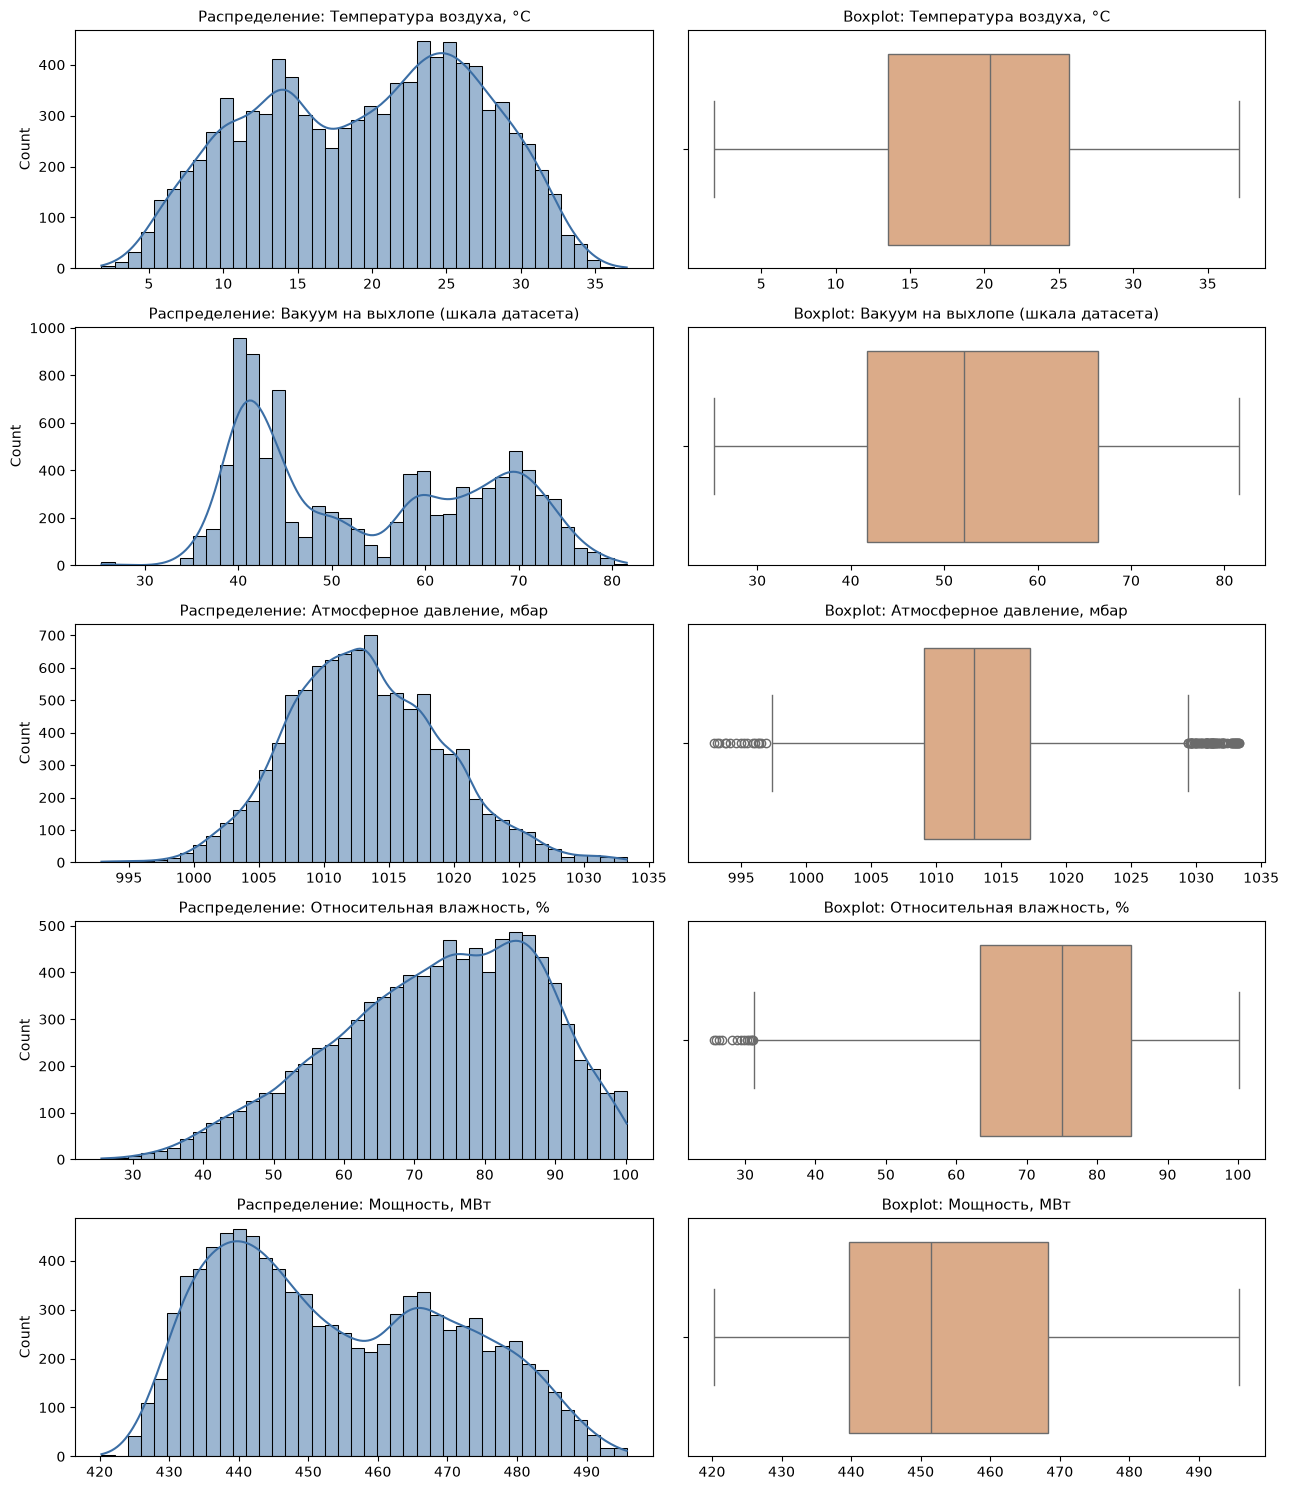

In [5]:
fig = eda.plot_distributions(df)
save(fig, "eda_distributions")
plt.show()

In [6]:
display(eda.iqr_outliers(df).to_frame())
modes = {col: [round(m, 1) for m in eda.histogram_modes(df[col])] for col in df.columns}
display(pd.Series(modes, name="центры мод").to_frame())

,выбросов по IQR
AT,0
V,0
AP,91
RH,13
PE,0


,центры мод
AT,"[14.2, 24.8]"
V,"[41.3, 50.7, 61.9, 69.4]"
AP,[1012.4]
RH,[84.0]
PE,"[439.1, 466.8]"


- **У мощности две моды** (около 439 и 467 МВт), у температуры две, у вакуума несколько. Разбиение стратифицируем по мощности, чтобы обе моды попали в тест в той же доле, что и в обучение.
- Причину мод (сезоны?) по этим данным проверить нельзя: времени в строках нет. Это гипотеза, а не факт.
- Асимметрия всех колонок меньше 0.5 по модулю: преобразования распределений не нужны.
- Выбросы по правилу IQR есть только у давления (91) и влажности (13). Это реальная погода, а не ошибки, — оставляем.

### 2.3 Связи с мощностью

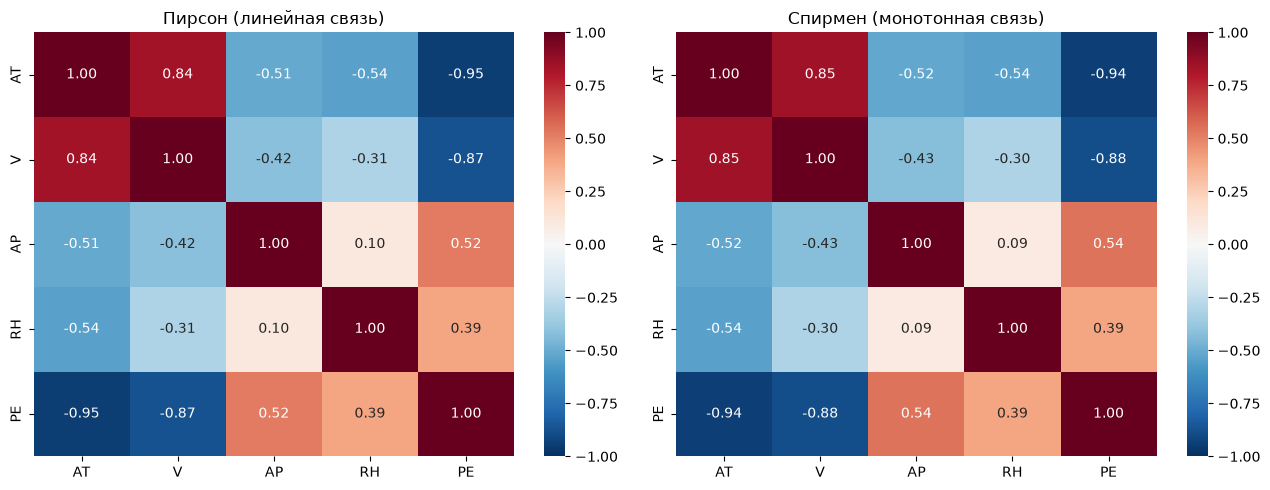

In [7]:
pearson, spearman = eda.correlation_tables(df)
fig = eda.plot_correlations(pearson, spearman)
save(fig, "eda_correlations")
plt.show()

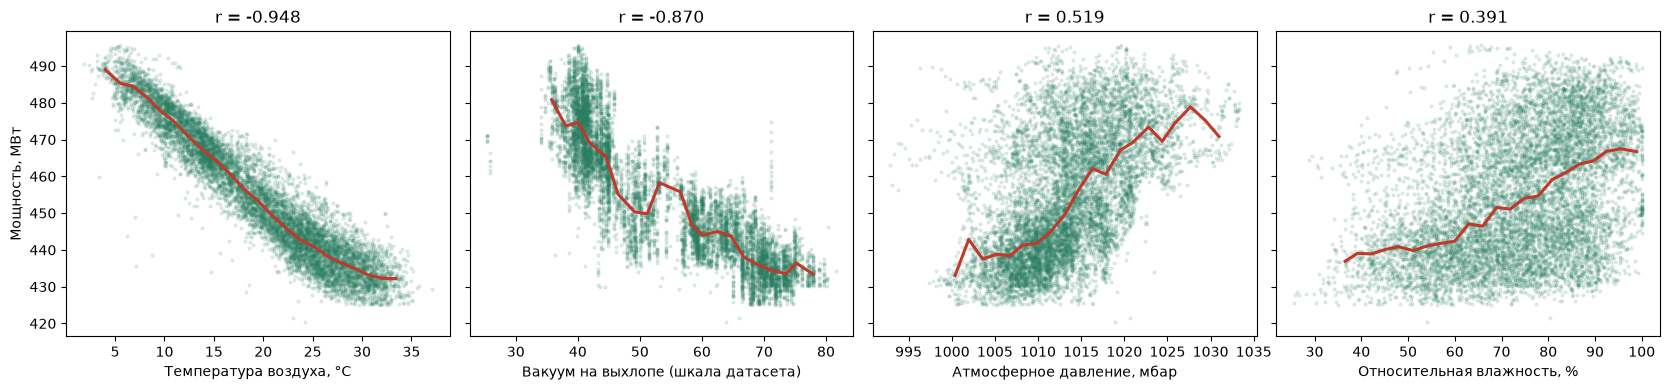

In [8]:
fig = eda.plot_target_relations(df, list(config.FEATURES_ALL))
save(fig, "eda_target_relations")
plt.show()

In [9]:
from sklearn.linear_model import LinearRegression

x_lin = df[["AT"]]
x_sq = df[["AT"]].assign(AT2=df["AT"] ** 2)
r2_lin = LinearRegression().fit(x_lin, df["PE"]).score(x_lin, df["PE"])
r2_sq = LinearRegression().fit(x_sq, df["PE"]).score(x_sq, df["PE"])
print(f"R² мощности от одной температуры: линейная {r2_lin:.4f}, с квадратом AT {r2_sq:.4f}")

R² мощности от одной температуры: линейная 0.8985, с квадратом AT 0.9067


- Одна температура объясняет около 90 % разброса мощности (R² ≈ 0.90).
- Связь слегка нелинейная: красная кривая медиан изгибается, квадрат температуры добавляет R². Поэтому в лестнице моделей есть полином и бустинг.
- Спирмен почти совпадает с Пирсоном: связи монотонные.

### 2.4 Мультиколлинеарность и частные корреляции

In [10]:
display(eda.variance_inflation(df, list(config.FEATURES_ALL)).round(2).to_frame())
partial = pd.DataFrame([
    {
        "признак": col,
        "сырая корреляция с PE": round(df[col].corr(df["PE"]), 3),
        "при фиксированной AT": round(eda.partial_correlation(df, col, "PE", ["AT"]), 3),
    }
    for col in ("V", "AP", "RH")
])
display(partial)

,VIF
AT,5.97
V,3.94
AP,1.45
RH,1.71


,признак,сырая корреляция с PE,при фиксированной AT
0,V,-0.870,-0.410
1,AP,0.519,0.135
2,RH,0.391,-0.466


- AT и V заметно связаны (VIF около 6 и 4). Перестановочная важность по одному признаку при такой связи занижает вклад обоих, поэтому важность считаем и по группе {AT, V}.
- **Влажность меняет знак.** Сырая корреляция с мощностью +0.39, а при фиксированной температуре −0.47. «Плюс» шёл через температуру: влажно бывает, когда холодно. По физике влажный воздух легче сухого, через компрессор проходит меньше массы, и мощность ниже.
- Давление и вакуум сохраняют знак и при фиксированной температуре: у них есть собственный вклад.

### 2.5 Проверка физики знаков

In [11]:
display(eda.physics_sign_check(df))

,признак,ожидаемый знак,корреляция с PE,сходится
0,AT,−,-0.948,True
1,V,−,-0.870,True
2,AP,+,0.519,True


Все знаки сходятся с физикой: жарче → меньше мощность, хуже вакуум → меньше, выше давление → больше.

### 2.6 Покрытие пространства признаков

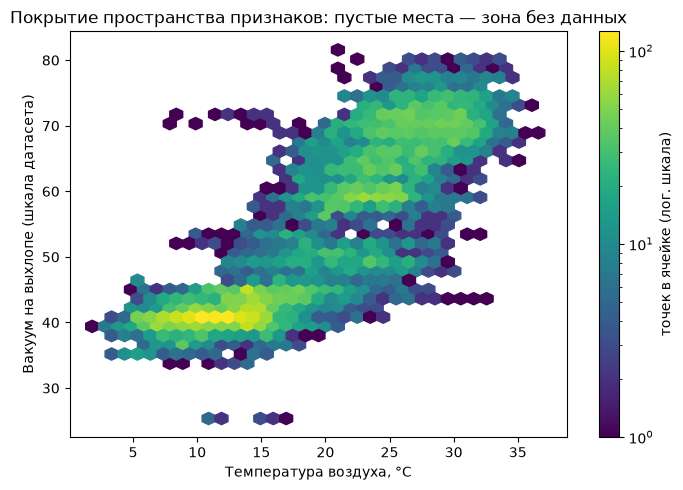

In [12]:
fig = eda.plot_coverage(df, "AT", "V")
save(fig, "eda_coverage_at_v")
plt.show()

In [13]:
for gap in eda.find_gaps(df["V"], min_width=2.0):
    print(f"V: пусто между {gap.low} и {gap.high}; ниже промежутка {gap.count_below} строк")
display(df[df["V"] < 30].describe().loc[["min", "mean", "max"]].round(2))
hot = df[df["AT"] > 30]
print(f"Жарких часов (AT > 30 °C): {len(hot)}, из них с V < 45: {(hot['V'] < 45).sum()}; "
      f"минимальный V в жару: {hot['V'].min()}")

V: пусто между 25.88 и 34.03; ниже промежутка 13 строк


,AT,V,AP,RH,PE
min,10.59,25.36,1008.27,65.47,460.97
mean,13.16,25.60,1009.17,85.04,467.15
max,16.61,25.88,1009.59,100.16,471.19


Жарких часов (AT > 30 °C): 733, из них с V < 45: 3; минимальный V в жару: 43.21


- Отдельный кластер V 25.4–25.9: 13 строк, у всех давление 1008–1010, похоже на один эпизод. Между 25.9 и 34.0 значений нет совсем.
- В жару вакуум всегда «плохой»: при AT > 30 °C значение V не ниже 43.2. Сочетание «жара + низкий V» — зона без данных. Модель там гадает, и страница должна об этом предупреждать.

### 2.7 Журнал решений

In [14]:
journal = (ROOT / "reports" / "decisions.md").read_text(encoding="utf-8")
display(Markdown(journal.split("\n", 1)[1]))


Решения приняты по итогам разведочного анализа, **до** обучения моделей. После того как увидим результаты на тесте, журнал не меняется. Цифры воспроизводятся в `notebooks/research.ipynb`, раздел 2.

| # | Находка | Решение |
|---|---|---|
| 1 | В `Folds5x2_pp.xlsx` 5 листов по 9 568 строк — одни и те же строки в разном порядке. Склейка даёт 47 840 строк, уникальных 9 527 | Берём один экземпляр: `data.csv` с UCI, он совпадает с первым листом. Листы не склеиваем |
| 2 | 41 точный дубль, конфликтов «тот же вход — другая мощность» нет | Удаляем дубли до разбиения, остаётся 9 527 строк |
| 3 | Пропусков нет, за границы контракта ничего не выходит | Чистка не нужна |
| 4 | RH больше 100% в 55 строках, максимум 100.16 | Оставляем: огрех датчика до 0.16 п.п., на модель не влияет. API принимает RH от 0 до 100 |
| 5 | По правилу IQR выбросы есть только у AP (91) и RH (13) | Оставляем: это реальная погода, а не ошибка, и в контракт значения укладываются |
| 6 | Асимметрия всех колонок меньше 0.5 по модулю | Преобразования распределений (PowerTransformer и т. п.) не применяем |
| 7 | Связь мощности с AT слегка нелинейная: R² линейной 0.8985, с квадратом AT 0.9067 | В лестнице моделей есть полином и бустинг |
| 8 | AT и V связаны: VIF 5.97 и 3.94, корреляция +0.84 | Важность считаем и по группе {AT, V}, а не только по одному признаку |
| 9 | Сырая корреляция RH с мощностью +0.39, а при фиксированной AT она −0.47 (при фиксированных AT и V −0.39) | «Плюс» влажности идёт через температуру. По физике влажный воздух легче, и мощность ниже. Знак проверяем по графикам частичной зависимости |
| 10 | Знаки AT (−), V (−) и AP (+) сходятся с физикой | Признаки в модели оставляем как есть |
| 11 | У мощности две моды, около 439 и 467 МВт. У AT две моды, у V несколько | Разбиение стратифицируем по 10 квантилям мощности |
| 12 | Отдельный кластер V 25.4–25.9: 13 строк, у всех AP 1008–1010, похоже на один эпизод. Между 25.9 и 34.0 значений нет | Строки оставляем, это реальные часы. Для V из промежутка 26–34 срабатывает предупреждение о новизне |
| 13 | При AT > 30 °C значение V не ниже 43.2: из 733 жарких часов только 3 с V < 45 | Сочетание «жара + низкий V» — зона без данных. Пресет «Небывалое сочетание» берём оттуда |
| 14 | Состав признаков | Задаёт физика, а не корреляции: модель плана — AT, AP, RH (вакуума на завтра никто не знает), эталон — AT, V, AP, RH |

## Решения после первого обучения (не по результатам теста)

| # | Находка | Решение |
|---|---|---|
| 15 | Полином 4-й степени, выбранный для модели плана, на краю данных загибается вверх: от 33 к 37 °C прогноз мощности растёт на 2 МВт даже при типичной жаркой погоде. Это противоречит физике, на графике страницы видно сразу | Модель обязана соблюдать физику: при росте температуры мощность не растёт (допуск 0.5 МВт на всём диапазоне AT при медианах остальных признаков). Модели, не прошедшие проверку, в выбор по правилу G2 не попадают. Бустинг получает ограничение монотонности по температуре (см. решение 17). Проверка смотрит на поведение модели, а не на тест |
| 16 | При значениях по умолчанию часть кривой «мощность от температуры» строится по сочетаниям погоды, которых в данных нет (например, жара при влажности 75%) | Такие участки кривой показываются серым пунктиром с подписью «таких часов в данных не было» |
| 17 | Опыт на 5-fold CV по обучающей части (тест не трогали), бустинг эталона: без ограничений RMSE 3.163; только температура ↓ — 3.166; только вакуум ↓ — 3.925; только давление ↑ — 3.360 | Ограничение монотонности ставим только по температуре: оно не стоит точности и совпадает с физической проверкой. Вакуум не ограничиваем: его шкала в датасете физически неоднозначна (раздел «Колонки» в описании данных). Давление не ограничиваем: при общем плюсе частный эффект в данных немонотонный |


## 3. Модели от простой к сложной

Две модели: **план** — без вакуума (его завтрашнего значения никто не знает) и **эталон** — со всеми параметрами. Для каждой — лестница от константы до стекинга. Гиперпараметры подбирались на 5-fold CV по обучающей части, метрики CV пересчитаны после подбора на другом разбиении на фолды. Тест (20%, стратифицирован по мощности) использован один раз — для этой таблицы. Модель выбирается правилом, зафиксированным до обучения: самая простая, чей RMSE на CV не хуже лучшего более чем на 5%.

In [15]:
import json

import numpy as np

PLAN, REF, NEUTRAL, INK = "#1d6fb8", "#b5651d", "#9aa5ae", "#1d2731"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e3e7ea", "grid.linewidth": 0.8, "axes.edgecolor": "#9aa5ae",
    "font.size": 12, "axes.titlesize": 13, "axes.titleweight": "bold",
})
metrics = json.loads(config.METRICS_PATH.read_text(encoding="utf-8"))


def ladder_table(set_name: str) -> pd.DataFrame:
    info = metrics["sets"][set_name]
    test = {row["name"]: row for row in info["test"]}
    chosen_base = info["chosen"].removesuffix(" + физика")
    mark = "да, с физическими признаками" if info["chosen"].endswith(" + физика") else "да"
    return pd.DataFrame([
        {
            "модель": row["name"],
            "RMSE на CV": round(row["RMSE"], 2),
            "± по фолдам": round(row["RMSE_std"], 2),
            "RMSE на тесте": round(test[row["name"]]["RMSE"], 2),
            "MAE на тесте": round(test[row["name"]]["MAE"], 2),
            "R² на тесте": round(test[row["name"]]["R2"], 4),
            "физика": "проходит" if row["physics_ok"] else "нарушает",
            "выбрана": mark if row["name"] == chosen_base else "",
        }
        for row in info["cv"]
    ])


display(Markdown("**План на завтра: AT, AP, RH (без вакуума)**"))
display(ladder_table("plan"))
display(Markdown("**Эталон: AT, V, AP, RH**"))
display(ladder_table("ref"))

**План на завтра: AT, AP, RH (без вакуума)**

,модель,RMSE на CV,± по фолдам,RMSE на тесте,MAE на тесте,R² на тесте,физика,выбрана
0,Константа,17.04,0.12,17.06,14.83,-0.000,проходит,
1,Линейная,4.81,0.07,4.78,3.79,0.921,проходит,
2,Полином + Ridge,4.49,0.10,4.44,3.48,0.932,нарушает,
3,Случайный лес,4.36,0.12,4.24,3.25,0.938,нарушает,
4,Градиентный бустинг,4.42,0.13,4.31,3.33,0.936,проходит,"да, с физическими признаками"
5,Стекинг (лес + бустинг),4.35,0.12,4.23,3.25,0.939,проходит,


**Эталон: AT, V, AP, RH**

,модель,RMSE на CV,± по фолдам,RMSE на тесте,MAE на тесте,R² на тесте,физика,выбрана
0,Константа,17.04,0.12,17.06,14.83,-0.000,проходит,
1,Линейная,4.58,0.09,4.47,3.56,0.931,проходит,
2,Полином + Ridge,4.17,0.11,4.03,3.15,0.944,нарушает,
3,Случайный лес,3.34,0.10,3.19,2.28,0.965,нарушает,
4,Градиентный бустинг,3.17,0.12,2.97,2.12,0.970,проходит,да
5,Стекинг (лес + бустинг),3.15,0.11,2.97,2.12,0.970,проходит,


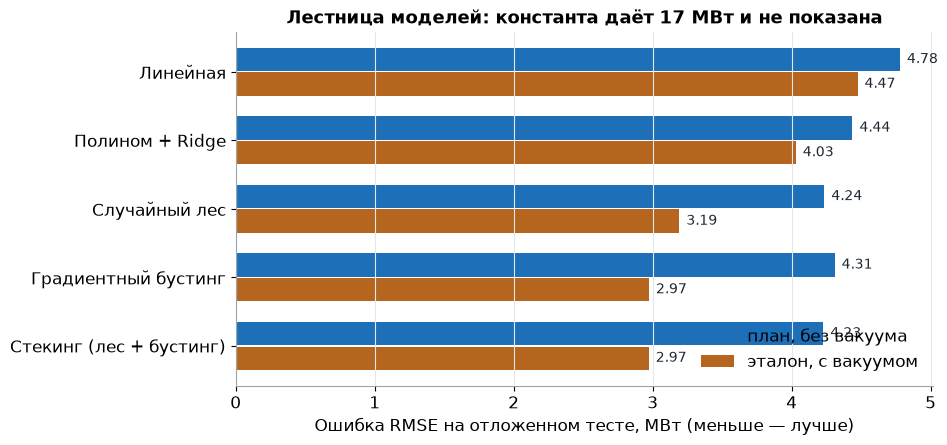

In [16]:
names = [row["name"] for row in metrics["sets"]["plan"]["test"] if row["name"] != "Константа"]
plan_rmse = {r["name"]: r["RMSE"] for r in metrics["sets"]["plan"]["test"]}
ref_rmse = {r["name"]: r["RMSE"] for r in metrics["sets"]["ref"]["test"]}
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(names))
ax.barh(y - 0.18, [plan_rmse[n] for n in names], height=0.34, color=PLAN, label="план, без вакуума")
ax.barh(y + 0.18, [ref_rmse[n] for n in names], height=0.34, color=REF, label="эталон, с вакуумом")
for i, n in enumerate(names):
    ax.text(plan_rmse[n] + 0.05, i - 0.18, f"{plan_rmse[n]:.2f}", va="center", fontsize=10, color=INK)
    ax.text(ref_rmse[n] + 0.05, i + 0.18, f"{ref_rmse[n]:.2f}", va="center", fontsize=10, color=INK)
ax.set_yticks(y, names)
ax.invert_yaxis()
ax.set_xlabel("Ошибка RMSE на отложенном тесте, МВт (меньше — лучше)")
ax.set_title("Лестница моделей: константа даёт 17 МВт и не показана")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="y", visible=False)
save(fig, "models_ladder")
plt.show()

In [17]:
plan_info, ref_info = metrics["sets"]["plan"], metrics["sets"]["ref"]
gain = 1 - ref_info["interval"]["test_metrics"]["RMSE"] / plan_info["interval"]["test_metrics"]["RMSE"]
failed = {name: [r["name"] for r in metrics["sets"][name]["cv"] if not r["physics_ok"]] for name in ("plan", "ref")}
lines = [
    f"- **Вакуум снижает ошибку на {gain:.0%}**, но на завтра его нет — поэтому для заявки нужна отдельная модель без него.",
    f"- Физическую проверку (мощность не растёт с жарой) не прошли: в плане — {', '.join(failed['plan']) or 'никто'}, в эталоне — {', '.join(failed['ref']) or 'никто'}. Они в выбор не попадают (решение 15 журнала).",
    f"- Среди прошедших правило выбрало: план — **{plan_info['chosen']}**, эталон — **{ref_info['chosen']}**.",
    "- Ориентир — статья авторов датасета (Tüfekci, 2014): лучшая модель MAE 2.82, RMSE 3.79 МВт. Протокол у них другой (5×2 CV, обучение на половине данных), поэтому сравниваем только по порядку величины.",
    f"- Физические признаки (плотность влажного воздуха, точка росы): RMSE плана {plan_info['physics']['rmse_base']:.3f} → {plan_info['physics']['rmse_physics']:.3f} ({'оставлены' if plan_info['physics']['kept'] else 'не оставлены'}), эталона {ref_info['physics']['rmse_base']:.3f} → {ref_info['physics']['rmse_physics']:.3f} ({'оставлены' if ref_info['physics']['kept'] else 'не оставлены'}). Порог — улучшение на 1% при соблюдении физики. Без вакуума плотность воздуха даёт модели плана полезный сигнал, а эталону хватает AT, AP, RH и V.",
]
display(Markdown("\n".join(lines)))

- **Вакуум снижает ошибку на 30%**, но на завтра его нет — поэтому для заявки нужна отдельная модель без него.
- Физическую проверку (мощность не растёт с жарой) не прошли: в плане — Полином + Ridge, Случайный лес, в эталоне — Полином + Ridge, Случайный лес. Они в выбор не попадают (решение 15 журнала).
- Среди прошедших правило выбрало: план — **Градиентный бустинг + физика**, эталон — **Градиентный бустинг**.
- Ориентир — статья авторов датасета (Tüfekci, 2014): лучшая модель MAE 2.82, RMSE 3.79 МВт. Протокол у них другой (5×2 CV, обучение на половине данных), поэтому сравниваем только по порядку величины.
- Физические признаки (плотность влажного воздуха, точка росы): RMSE плана 4.416 → 4.346 (оставлены), эталона 3.168 → 3.167 (не оставлены). Порог — улучшение на 1% при соблюдении физики. Без вакуума плотность воздуха даёт модели плана полезный сигнал, а эталону хватает AT, AP, RH и V.

### 3.1 Ловушка с листами в цифрах

Случайный лес, тест 20%: склеили 5 листов — RMSE 0.28 МВт, честно — 3.45 МВт


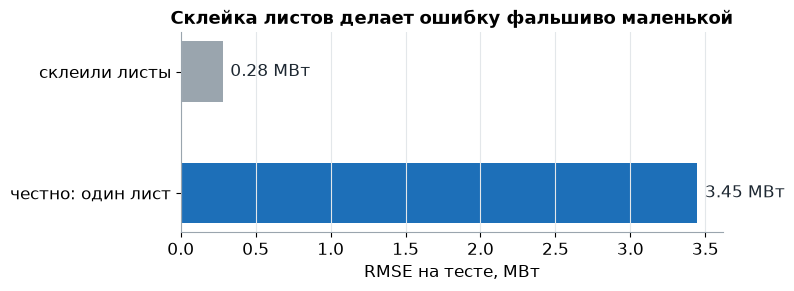

In [18]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split


def forest_rmse(frame: pd.DataFrame) -> float:
    x, y = frame[list(config.FEATURES_ALL)], frame["PE"]
    x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.2, random_state=config.SEED)
    model = RandomForestRegressor(n_estimators=100, random_state=config.SEED, n_jobs=-1).fit(x_tr, y_tr)
    return float(np.sqrt(np.mean((y_te - model.predict(x_te)) ** 2)))


glued_rmse, honest_rmse = forest_rmse(glued.round(4)), forest_rmse(df)
print(f"Случайный лес, тест 20%: склеили 5 листов — RMSE {glued_rmse:.2f} МВт, честно — {honest_rmse:.2f} МВт")
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh([1, 0], [glued_rmse, honest_rmse], color=[NEUTRAL, PLAN], height=0.5)
ax.set_yticks([1, 0], ["склеили листы", "честно: один лист"])
for value, pos in ((glued_rmse, 1), (honest_rmse, 0)):
    ax.text(value + 0.05, pos, f"{value:.2f} МВт", va="center", color=INK)
ax.set_xlabel("RMSE на тесте, МВт")
ax.set_title("Склейка листов делает ошибку фальшиво маленькой")
ax.grid(axis="y", visible=False)
save(fig, "trap")
plt.show()

Склеенный тест почти целиком состоит из строк, которые модель уже видела при обучении, — отсюда «точность», которой на новых данных не будет.

In [19]:
from sklearn.base import clone

from powerplant.data import split_holdout
from powerplant.models import build_ladder, build_stacking, with_physics

split = split_holdout(df, stratify_bins=10)  # то же разбиение, что в обучении
tuned = json.loads((config.MODELS_DIR / "tuned_params.json").read_text())["params"]


def tuned_model(set_name: str, name: str):
    """Необученная модель лестницы с подобранными параметрами — для разделов ниже."""
    if name.endswith(" + физика"):
        return with_physics(tuned_model(set_name, name.removesuffix(" + физика")))
    features = config.FEATURES_PLAN if set_name == "plan" else config.FEATURES_ALL
    ladder = {c.name: c for c in build_ladder(config.SEED, features=features)}
    if name.startswith("Стекинг"):
        return build_stacking(tuned_model(set_name, "Случайный лес"), tuned_model(set_name, "Градиентный бустинг"), config.SEED)
    return clone(ladder[name].estimator).set_params(**tuned[set_name].get(name, {}))

### 3.2 Сравнение со статьёй по её протоколу

Авторы датасета сравнивали модели проверкой 5×2: на каждом из пяти листов обучение на одной половине и проверка на другой, и наоборот — 10 измерений. Повторяем этот протокол для выбранного эталона на тех же листах. Это только сравнение: на выбор модели оно не влияло (выбор сделан раньше по CV).

In [20]:
ref_template = tuned_model("ref", metrics["sets"]["ref"]["chosen"])
maes, rmses = [], []
for frame in sheets.values():
    half = len(frame) // 2
    for train_part, test_part in ((frame.iloc[:half], frame.iloc[half:]), (frame.iloc[half:], frame.iloc[:half])):
        model = clone(ref_template).fit(train_part[list(config.FEATURES_ALL)], train_part["PE"])
        error = test_part["PE"].to_numpy() - model.predict(test_part[list(config.FEATURES_ALL)])
        maes.append(np.mean(np.abs(error)))
        rmses.append(np.sqrt(np.mean(error ** 2)))
paper_table = pd.DataFrame({
    "MAE, МВт": [np.mean(maes), 2.818], "RMSE, МВт": [np.mean(rmses), 3.787],
}, index=[f"наш эталон ({metrics['sets']['ref']['chosen'].lower()}), 5×2", "статья: Bagging REP Tree, 5×2"]).round(3)
display(paper_table)
paper_result = {"mae": float(np.mean(maes)), "rmse": float(np.mean(rmses))}

,"MAE, МВт","RMSE, МВт"
"наш эталон (градиентный бустинг), 5×2",2.297,3.233
"статья: Bagging REP Tree, 5×2",2.818,3.787


Цифры статьи — из вторичного источника (обзор PMC10558780). Внутри одного листа есть 41 дубль, при делении пополам часть из них попадает в обе половины — у нас и у авторов одинаково.

## 4. Что сильнее всего влияет на мощность

Три способа, не зависящих от выбранной модели:
1. **Перестановочная важность** на валидационных частях фолдов: насколько вырастает ошибка, если перемешать значения параметра. AT и V связаны, поэтому пара {AT, V} перемешивается и вместе.
2. **Графики частичной зависимости** — форма и знак влияния.
3. **Коэффициенты линейной модели** на стандартизированных признаках.

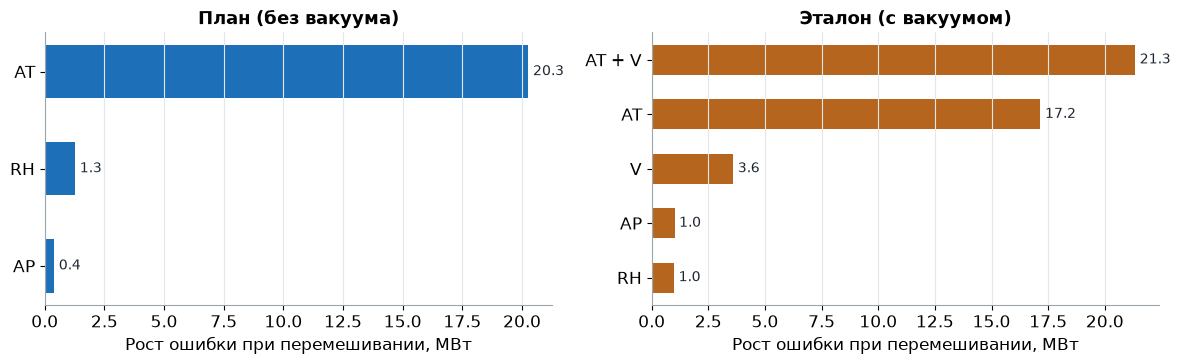

,параметр,"рост ошибки, МВт",разброс
0,AT,20.26,0.46
1,RH,1.27,0.10
2,AP,0.39,0.04


,параметр,"рост ошибки, МВт",разброс
0,AT + V,21.34,0.32
1,AT,17.16,0.32
2,V,3.60,0.34
3,AP,1.01,0.09
4,RH,0.99,0.09


In [21]:
def importance_table(set_name: str) -> pd.DataFrame:
    rows = metrics["sets"][set_name]["importance"]["permutation"]
    return pd.DataFrame(rows).rename(columns={"group": "параметр", "rmse_increase": "рост ошибки, МВт", "std": "разброс"}).round(2)


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, set_name, color, title in ((axes[0], "plan", PLAN, "План (без вакуума)"), (axes[1], "ref", REF, "Эталон (с вакуумом)")):
    table = importance_table(set_name).sort_values("рост ошибки, МВт")
    ax.barh(table["параметр"], table["рост ошибки, МВт"], color=color, height=0.55)
    for pos, value in enumerate(table["рост ошибки, МВт"]):
        ax.text(value + 0.2, pos, f"{value:.1f}", va="center", color=INK, fontsize=10)
    ax.set_title(title)
    ax.set_xlabel("Рост ошибки при перемешивании, МВт")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "importance")
plt.show()
display(importance_table("plan"))
display(importance_table("ref"))

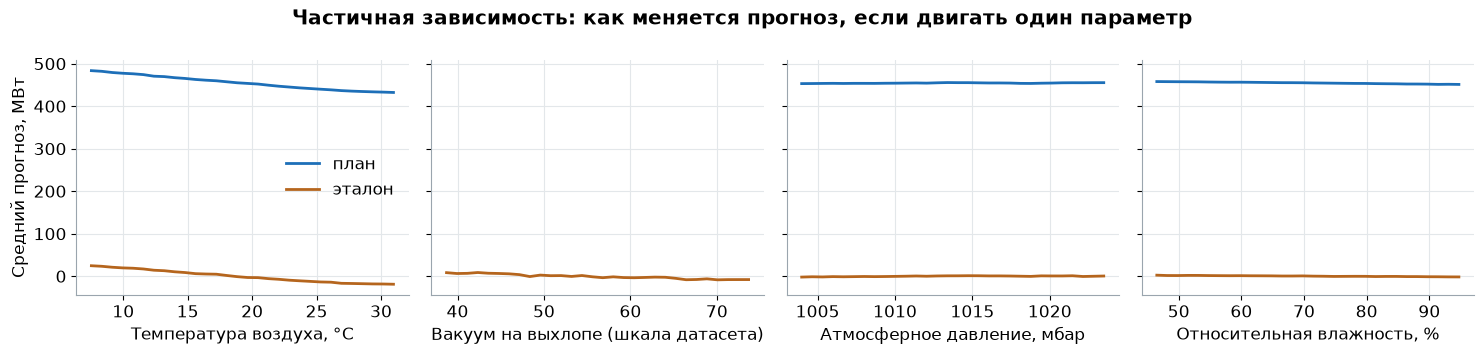

,"план, МВт на единицу","эталон, МВт на единицу","план, % мощности на единицу"
AT,-2.311,-2.008,-0.509
V,NaN,-0.500,NaN
AP,0.082,0.105,0.018
RH,-0.144,-0.077,-0.032


**Линейная модель: МВт на одно стандартное отклонение признака**

,plan,ref
AT,-17.72,-14.79
AP,0.13,0.34
RH,-2.99,-2.33
V,NaN,-2.92


In [22]:
pdp_plan, pdp_ref = metrics["sets"]["plan"]["importance"]["pdp"], metrics["sets"]["ref"]["importance"]["pdp"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, col in zip(axes, config.FEATURES_ALL, strict=True):
    if col in pdp_plan:
        ax.plot(pdp_plan[col]["grid"], pdp_plan[col]["value"], color=PLAN, linewidth=2, label="план")
    ax.plot(pdp_ref[col]["grid"], pdp_ref[col]["value"], color=REF, linewidth=2, label="эталон")
    ax.set_xlabel(config.FEATURE_LABELS[col])
axes[0].set_ylabel("Средний прогноз, МВт")
axes[0].legend(frameon=False)
fig.suptitle("Частичная зависимость: как меняется прогноз, если двигать один параметр", fontweight="bold")
fig.tight_layout()
save(fig, "pdp")
plt.show()
mean_power = df["PE"].mean()
slopes = pd.DataFrame({
    name: {col: metrics["sets"][name]["importance"]["pdp_slope_mw_per_unit"].get(col, np.nan) for col in config.FEATURES_ALL}
    for name in ("plan", "ref")
}).rename(columns={"plan": "план, МВт на единицу", "ref": "эталон, МВт на единицу"})
slopes["план, % мощности на единицу"] = slopes["план, МВт на единицу"] / mean_power * 100
display(slopes.round(3))
coefficients = pd.DataFrame({name: metrics["sets"][name]["importance"]["coefficients"] for name in ("plan", "ref")})
display(Markdown("**Линейная модель: МВт на одно стандартное отклонение признака**"))
display(coefficients.round(2))

**Физика.**
- **Температура (AT)** — главный фактор в обоих способах. Горячий воздух менее плотный, через компрессор газовой турбины проходит меньше массы, и мощность падает. В модели плана наклон по AT — полный эффект: в него входит и ухудшение охлаждения конденсатора, которое в эталоне видно через V. Наш наклон в модели плана — около 0.5% мощности на 1 °C (таблица выше). Ориентиры из литературы: 0.27% на 1 °C для одной иранской ПГУ и 0.5–0.9% для отдельной газовой турбины (низкая–средняя уверенность источника). Чувствительность зависит от конструкции станции, поэтому это ориентир, а не проверка.
- **Вакуум (V)** — второй фактор эталона: хуже вакуум → меньше перепад на паровой турбине → меньше мощность. Вместе с AT пара объясняет основную часть разброса — поэтому её важность считается и совместно.
- **Давление (AP)** — выше давление → плотнее воздух → больше мощность. Влияние небольшое, но со стабильным знаком.
- **Влажность (RH)** — вклад около 1 МВт, как у давления. При фиксированной температуре влажный воздух даёт меньше мощности (раздел 2.4): частичная зависимость и линейный коэффициент показывают тот же знак, минус.

## 5. Диапазон «от … до …»

Диапазон 90% строится по внефолдовым остаткам обучающей части (конформный подход с поправкой на конечную выборку) и проверяется на отложенном тесте. Ширина одна для всех условий, поэтому отдельно смотрим покрытие по третям AT, V и RH.

,модель,"полуширина q, МВт",покрытие на тесте,G3 (0.88–0.92)
0,план,6.93,0.913,True
1,эталон,4.65,0.911,True


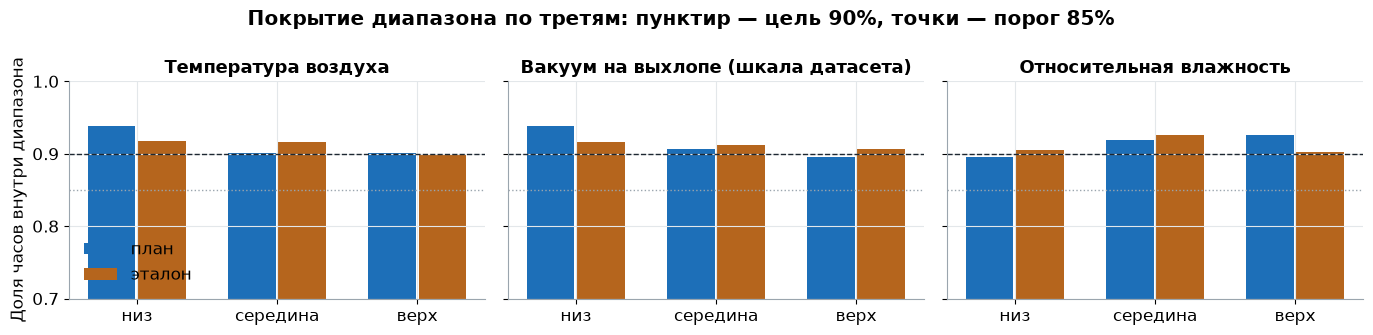

Срезы ниже 85% (G3b): нет


In [23]:
rows = []
for name, title in (("plan", "план"), ("ref", "эталон")):
    info = metrics["sets"][name]["interval"]
    rows.append({"модель": title, "полуширина q, МВт": round(info["q_mw"], 2),
                 "покрытие на тесте": round(info["coverage_test"], 3),
                 "G3 (0.88–0.92)": 0.88 <= info["coverage_test"] <= 0.92})
display(pd.DataFrame(rows))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), sharey=True)
for ax, col in zip(axes, ("AT", "V", "RH"), strict=True):
    for offset, name, color, title in ((-0.18, "plan", PLAN, "план"), (0.18, "ref", REF, "эталон")):
        table = pd.DataFrame(metrics["sets"][name]["interval"]["slices_test"][col])
        ax.bar(np.arange(len(table)) + offset, table["покрытие"], width=0.34, color=color, label=title)
    ax.axhline(0.9, color=INK, linewidth=1, linestyle="--")
    ax.axhline(0.85, color=NEUTRAL, linewidth=1, linestyle=":")
    ax.set_xticks(range(len(table)), table["срез"])
    ax.set_title(config.FEATURE_LABELS[col].split(",")[0])
    ax.set_ylim(0.7, 1.0)
axes[0].set_ylabel("Доля часов внутри диапазона")
axes[0].legend(frameon=False, loc="lower left")
fig.suptitle("Покрытие диапазона по третям: пунктир — цель 90%, точки — порог 85%", fontweight="bold")
fig.tight_layout()
save(fig, "coverage")
plt.show()
low_slices = [
    (name, col, row["срез"], round(row["покрытие"], 3))
    for name in ("plan", "ref") for col in ("AT", "V", "RH")
    for row in metrics["sets"][name]["interval"]["slices_test"][col] if row["покрытие"] < 0.85
]
print("Срезы ниже 85% (G3b):", low_slices or "нет")

Покрытие — про модель на 80% данных. Боевая модель обучена на всех строках, кроме демо-файла, и её полуширина пересчитана по внефолдовым остаткам на этих данных (поле `service` в `models/metrics.json`). Ограничения: строки считаются независимыми (времени в данных нет), а диапазон описывает ошибку модели при **точной** погоде — ошибку прогноза погоды добавляет следующий раздел.

### 5.1 Почему не интервал по деревьям леса

Популярный совет — брать 5-й и 95-й перцентили прогнозов отдельных деревьев случайного леса. Проверяем на тесте, сколько часов такой «интервал 90%» реально накрывает, и сравниваем с конформным диапазоном для того же леса.

In [24]:
from sklearn.model_selection import KFold, cross_val_predict

from powerplant.intervals import conformal_quantile

forest = tuned_model("ref", "Случайный лес")
x_tr, y_tr = split.train[list(config.FEATURES_ALL)], split.train["PE"]
x_te, y_te = split.test[list(config.FEATURES_ALL)], split.test["PE"].to_numpy()
forest.fit(x_tr, y_tr)
per_tree = np.stack([tree.predict(x_te.to_numpy()) for tree in forest.estimators_])
low, high = np.percentile(per_tree, 5, axis=0), np.percentile(per_tree, 95, axis=0)
trees_cov = np.mean((y_te >= low) & (y_te <= high))
oof = cross_val_predict(clone(forest), x_tr, y_tr, cv=KFold(5, shuffle=True, random_state=config.SEED))
q_forest = conformal_quantile(y_tr.to_numpy() - oof)
pred = forest.predict(x_te)
conf_cov = np.mean(np.abs(y_te - pred) <= q_forest)
display(pd.DataFrame({
    "покрытие на тесте": [trees_cov, conf_cov],
    "средняя ширина, МВт": [np.mean(high - low), 2 * q_forest],
}, index=["перцентили деревьев (5–95%)", "конформный, 90%"]).round(3))
trees_result = {"trees_coverage": float(trees_cov), "conformal_coverage": float(conf_cov),
                "trees_width": float(np.mean(high - low)), "conformal_width": float(2 * q_forest)}

,покрытие на тесте,"средняя ширина, МВт"
перцентили деревьев (5–95%),0.881,10.369
"конформный, 90%",0.906,10.109


Разброс между деревьями показывает неуверенность самой модели, а шум данных учитывает лишь косвенно: такой интервал накрывает меньше заявленных 90% и при этом шире. Конформный диапазон держит уровень при меньшей ширине — поэтому на странице именно он.

## 6. Стресс-тест: что будет, если ошибётся прогноз погоды

План на завтра строится по прогнозу погоды, а не по замеру. Добавляем к температуре на тесте случайную ошибку и смотрим, как растёт ошибка прогноза мощности и сужается реальное покрытие диапазона. Это синтетика для проверки устойчивости — модель на ней не учится.

,"ошибка прогноза AT, °C (σ)","MAE модели плана, МВт","MAE поправки по одной AT, МВт",покрытие диапазона
0,0.0,3.265,4.300,0.913
1,1.0,3.742,4.615,0.861
2,2.0,4.833,5.501,0.752
3,3.0,6.142,6.738,0.644


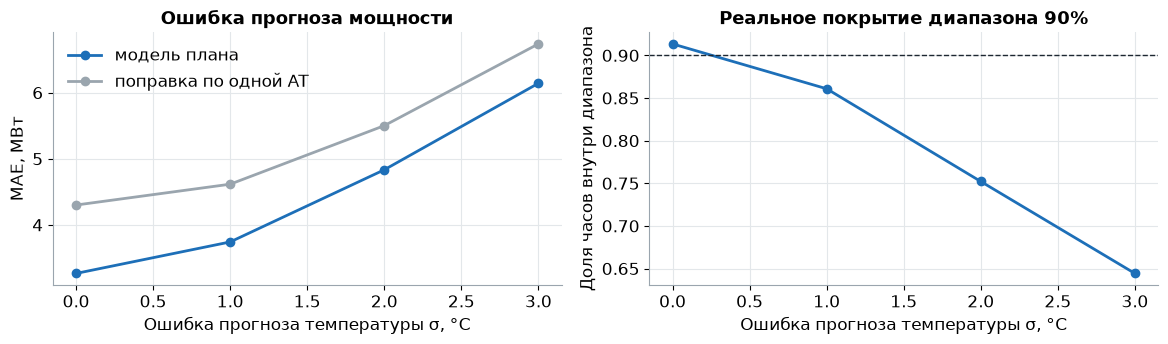

In [25]:
from sklearn.linear_model import LinearRegression

plan_model = tuned_model("plan", metrics["sets"]["plan"]["chosen"])
plan_model.fit(split.train[list(config.FEATURES_PLAN)], split.train["PE"])
base_at = LinearRegression().fit(split.train[["AT"]], split.train["PE"])  # «поправка по температуре»
q_plan = metrics["sets"]["plan"]["interval"]["q_mw"]
rng = np.random.default_rng(config.SEED)
rows = []
for sigma in (0.0, 1.0, 2.0, 3.0):
    maes, maes_base, covs = [], [], []
    for _ in range(20):
        noisy = split.test.assign(AT=split.test["AT"] + rng.normal(0, sigma, len(split.test)))
        pred = plan_model.predict(noisy[list(config.FEATURES_PLAN)])
        maes.append(np.mean(np.abs(split.test["PE"] - pred)))
        maes_base.append(np.mean(np.abs(split.test["PE"] - base_at.predict(noisy[["AT"]]))))
        covs.append(np.mean(np.abs(split.test["PE"] - pred) <= q_plan))
    rows.append({"ошибка прогноза AT, °C (σ)": sigma, "MAE модели плана, МВт": np.mean(maes),
                 "MAE поправки по одной AT, МВт": np.mean(maes_base), "покрытие диапазона": np.mean(covs)})
stress = pd.DataFrame(rows)
display(stress.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(stress.iloc[:, 0], stress.iloc[:, 1], marker="o", color=PLAN, linewidth=2, label="модель плана")
axes[0].plot(stress.iloc[:, 0], stress.iloc[:, 2], marker="o", color=NEUTRAL, linewidth=2, label="поправка по одной AT")
axes[0].set_xlabel("Ошибка прогноза температуры σ, °C")
axes[0].set_ylabel("MAE, МВт")
axes[0].set_title("Ошибка прогноза мощности")
axes[0].legend(frameon=False)
axes[1].plot(stress.iloc[:, 0], stress.iloc[:, 3], marker="o", color=PLAN, linewidth=2)
axes[1].axhline(0.9, color=INK, linestyle="--", linewidth=1)
axes[1].set_xlabel("Ошибка прогноза температуры σ, °C")
axes[1].set_ylabel("Доля часов внутри диапазона")
axes[1].set_title("Реальное покрытие диапазона 90%")
fig.tight_layout()
save(fig, "stress")
plt.show()

Чем хуже прогноз погоды, тем шире реальный разброс: в рабочем внедрении полосу для заявки нужно расширять на ошибку прогноза погоды конкретного поставщика. Модель при этом остаётся лучше простой поправки по одной температуре при любой ошибке.

## 7. Контроль оборудования: суточное правило

Одиночный час ниже нижней границы диапазона случается примерно в 5% часов и на здоровой станции — это тревога каждые сутки. Поэтому тревогу даём по среднему отклонению факта от эталона за сутки: порог выбран так, чтобы на здоровой станции срабатывал 1% суточных окон. Проверка — на искусственных поломках: к внефолдовым остаткам добавляем устойчивое падение мощности на 1, 2 и 3%.

Порог: среднее (факт − эталон) за 24 ч ниже -1.72 МВт


,доля пойманных за сутки
1%,1.0
2%,1.0
3%,1.0


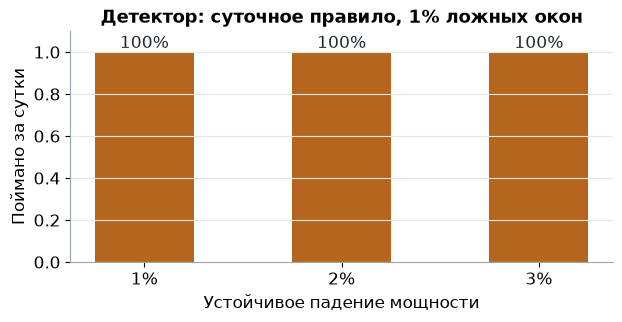

In [26]:
detector = metrics["detector"]
print(f"Порог: среднее (факт − эталон) за {detector['window_h']} ч ниже {detector['threshold_mw']:.2f} МВт")
rates = pd.Series(detector["detection_rate_by_drop"], name="доля пойманных за сутки")
display(rates.to_frame())
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(rates.index, rates.values, color=REF, width=0.5)
for pos, value in enumerate(rates.values):
    ax.text(pos, value + 0.02, f"{value:.0%}", ha="center", color=INK)
ax.set_ylim(0, 1.1)
ax.set_xlabel("Устойчивое падение мощности")
ax.set_ylabel("Поймано за сутки")
ax.set_title("Детектор: суточное правило, 1% ложных окон")
ax.grid(axis="x", visible=False)
save(fig, "detector")
plt.show()

In [27]:
from powerplant.artifact import load_bundle
from powerplant.service import ForecastService

service = ForecastService(load_bundle())
example = service.batch("example.csv", service.example_csv().encode())
s = example.summary
print(f"Демо-файл: {s.rows} ч, строки, которых модель не видела; со второй половины мощность снижена на 2%.")
print(f"Тревога с {s.first_alarm_hour}-го часа, всего {s.alarm_hours} ч; недобор {s.lost_mwh} МВт·ч.")

Демо-файл: 168 ч, строки, которых модель не видела; со второй половины мощность снижена на 2%.
Тревога с 91-го часа, всего 78 ч; недобор 828.8 МВт·ч.


In [28]:
from powerplant.detector import detection_rate

mean_power = float(df["PE"].mean())
sensitivity = pd.DataFrame([
    {"падение, %": share * 100, "падение, МВт": share * mean_power,
     "поймано за сутки": detection_rate(service.bundle.reference.residuals, 24,
                                        service.bundle.detector_threshold, -share * mean_power)}
    for share in (0.002, 0.003, 0.004, 0.005, 0.0075, 0.01)
])
display(Markdown("**Чувствительность: какое падение правило замечает за сутки**"))
display(sensitivity.round(3))

**Чувствительность: какое падение правило замечает за сутки**

,"падение, %","падение, МВт",поймано за сутки
0,0.20,0.909,0.085
1,0.30,1.363,0.252
2,0.40,1.817,0.545
3,0.50,2.272,0.817
4,0.75,3.408,0.998
5,1.00,4.543,1.000


Ограничения: окна собраны из независимых остатков, реальные часы связаны между собой — на живом потоке ложных тревог будет больше; «прочее» включает и ошибку самого эталона, поэтому тревога — сигнал проверить оборудование, а не диагноз.

## 8. Экономика внедрения

Что считаем сами — МВт·ч и МВт. Цены и доли потерь — параметры. Механика из источника: отклонение фактической выработки от планового почасового объёма по собственной инициативе оплачивается по невыгодной цене (Правила ОРЭМ, ПП РФ №1172, п. 137, 140–141). Цена РСВ первой ценовой зоны — около 1 747 ₽/МВт·ч в среднем за 2024 год (по отраслевым источникам, требует сверки). **Доля потери на невыгодной цене (k) — допущение**, показываем вилку.

In [29]:
from powerplant.economics import (
    degradation_loss_rub, forecast_error_saved_mwh, payback_months, revenue_rub, vacuum_loss_profile,
)

PRICE = config.PRICE_RUB_PER_MWH
const_mae = next(r["MAE"] for r in metrics["sets"]["plan"]["test"] if r["name"] == "Константа")
rows = []
for sigma in (0.0, 2.0):
    row = stress.set_index("ошибка прогноза AT, °C (σ)").loc[sigma]
    for base_name, base_mae in (("константа (потолок эффекта)", const_mae), ("поправка по одной AT", row["MAE поправки по одной AT, МВт"])):
        saved = forecast_error_saved_mwh(base_mae, row["MAE модели плана, МВт"], hours=1000)
        rows.append({"ошибка прогноза AT σ, °C": sigma, "с чем сравниваем": base_name,
                     "меньше ошибки, МВт·ч на 1000 ч": round(saved),
                     **{f"₽ при k={k}": round(revenue_rub(saved, PRICE, k)) for k in (0.1, 0.25, 1.0)}})
econ_a = pd.DataFrame(rows)
display(Markdown("**(А) Точнее заявка: на 1 000 часов работы на полной нагрузке**"))
display(econ_a)

**(А) Точнее заявка: на 1 000 часов работы на полной нагрузке**

,"ошибка прогноза AT σ, °C",с чем сравниваем,"меньше ошибки, МВт·ч на 1000 ч",₽ при k=0.1,₽ при k=0.25,₽ при k=1.0
0,0.0,константа (потолок эффекта),11561,2019692,5049231,20196924
1,0.0,поправка по одной AT,1035,180795,451988,1807952
2,2.0,константа (потолок эффекта),9993,1745739,4364349,17457394
3,2.0,поправка по одной AT,668,116668,291670,1166680


In [30]:
PLANT_MW = 463.9  # Ярославская ТЭС (ПГУ-450), установленная мощность по открытым данным — для масштаба
rates = metrics["detector"]["detection_rate_by_drop"]
rows = []
for share, label in ((0.01, "1%"), (0.02, "2%"), (0.03, "3%")):
    rows.append({"падение мощности": label,
                 "поймано за сутки": f"{rates[label]:.0%}",
                 "потери за сутки, ₽": round(degradation_loss_rub(PLANT_MW, share, 24, PRICE)),
                 "потери за неделю без контроля, ₽": round(degradation_loss_rub(PLANT_MW, share, 24 * 7, PRICE)),
                 "потери за месяц без контроля, ₽": round(degradation_loss_rub(PLANT_MW, share, 24 * 30, PRICE))})
econ_b = pd.DataFrame(rows)
display(Markdown("**(Б) Раннее обнаружение деградации** — станция масштаба 463.9 МВт, оценка выручки, не прибыли"))
display(econ_b)

**(Б) Раннее обнаружение деградации** — станция масштаба 463.9 МВт, оценка выручки, не прибыли

,падение мощности,поймано за сутки,"потери за сутки, ₽","потери за неделю без контроля, ₽","потери за месяц без контроля, ₽"
0,1%,100%,194504,1361528,5835120
1,2%,100%,389008,2723056,11670240
2,3%,100%,583512,4084584,17505359


In [31]:
ref_model = tuned_model("ref", metrics["sets"]["ref"]["chosen"])
ref_model.fit(split.train[list(config.FEATURES_ALL)], split.train["PE"])
profile = vacuum_loss_profile(plan_model.predict(split.test[list(config.FEATURES_PLAN)]),
                              ref_model.predict(split.test[list(config.FEATURES_ALL)]), worst_share=0.1)
display(Markdown("**(В) Вакуум** — на тесте, модели обучены на обучающей части"))
print(f"В {profile['share_hours_worse']:.0%} часов вакуум хуже обычного для такой погоды, "
      f"в среднем это −{profile['mean_loss_when_worse_mw']:.1f} МВт.")
print(f"В 10% худших часов вакуум отнимает в среднем {profile['worst_mean_loss_mw']:.1f} МВт "
      f"≈ {profile['worst_mean_loss_mw'] * PRICE:,.0f} ₽ в час.".replace(",", " "))

**(В) Вакуум** — на тесте, модели обучены на обучающей части

В 51% часов вакуум хуже обычного для такой погоды, в среднем это −2.2 МВт.
В 10% худших часов вакуум отнимает в среднем 5.0 МВт ≈ 8 821 ₽ в час.


In [32]:
display(Markdown("**(Г) Окупаемость** — сетка сценариев: затраты на внедрение и годовой эффект — допущения"))
costs = [500_000, 1_000_000, 2_000_000]
effects = [1_000_000, 3_000_000, 10_000_000]
grid = pd.DataFrame({f"эффект {e / 1e6:g} млн ₽/год": [round(payback_months(c, e), 1) for c in costs] for e in effects},
                    index=[f"затраты {c / 1e6:g} млн ₽" for c in costs])
display(grid)

**(Г) Окупаемость** — сетка сценариев: затраты на внедрение и годовой эффект — допущения

,эффект 1 млн ₽/год,эффект 3 млн ₽/год,эффект 10 млн ₽/год
затраты 0.5 млн ₽,6.0,2.0,0.6
затраты 1 млн ₽,12.0,4.0,1.2
затраты 2 млн ₽,24.0,8.0,2.4


In [33]:
summary = {
    "trap": {"glued_rmse": glued_rmse, "honest_rmse": honest_rmse},
    "stress": stress.to_dict(orient="records"),
    "vacuum": profile,
    "economics_a": econ_a.to_dict(orient="records"),
    "economics_b": econ_b.to_dict(orient="records"),
    "plant_mw": PLANT_MW,
    "price": PRICE,
    "demo": {"rows": s.rows, "first_alarm_hour": s.first_alarm_hour, "alarm_hours": s.alarm_hours},
    "paper": paper_result,
    "trees": trees_result,
    "detector_sensitivity": sensitivity.to_dict(orient="records"),
}
(ROOT / "reports" / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2, default=float), encoding="utf-8")
print("Сводка для слайдов сохранена: reports/summary.json")

Сводка для слайдов сохранена: reports/summary.json


**Как читать.** Наши цифры — МВт·ч меньше ошибки и МВт, которые теряются из-за вакуума и деградации. В рубли они переводятся ценой и долей потерь: цена — из открытых источников, доля потерь и затраты на внедрение — допущения, которые стоит уточнить у эксперта кейса. Модель лёгкая: работает на обычном компьютере, данные берёт из уже существующей АСУ ТП и прогноза погоды.